# 50 Extreme Frequency Grid-Cell Distributions

In [15]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

from cdrmip_extremes import (
    utils, stats, io_disk, plotting, load_raw
)
from cdrmip_extremes.configs import CDR_MODELS, PROC_DIR, FIG_DIR

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

In [3]:
base = PROC_DIR / 'CDRMIP' / 'extremes'
varname = 'tas'

ext_data = {
    name: io_disk.load_nested(base / name, f"{varname}_{name}", order=CDR_MODELS)
    for name in ['exceedances_median_multimodel',
                 'branch_differences_median_multimodel',
                 'agreement']
}

In [4]:
exceedances = ext_data['exceedances_median_multimodel']
differences = ext_data['branch_differences_median_multimodel']
agreement = ext_data['agreement']

In [9]:
land_mask,ocean_mask = load_raw.load_land_ocean_masks()

Searching for files matching: {'experiment_id': '1pctCO2-cdr', 'source_id': 'ACCESS-ESM1-5', 'member_id': 'r1i1p1f1', 'table_id': 'fx', 'variable_id': ['sftlf'], 'grid_label': 'gn'}
Loading ACCESS-ESM1-5 / r1i1p1f1
Building regridder for grid (145,) x (192,)


## Create distributions

In [11]:
def binned_area_fraction(da, bins):
    """Area-weighted % of global surface falling in each bin."""
    weights = np.cos(np.deg2rad(da.lat)).broadcast_like(da).values.flatten()
    vals = da.values.flatten()
    valid = ~np.isnan(vals)
    counts, _ = np.histogram(vals[valid], bins=bins, weights=weights[valid])
    return counts / weights[valid].sum() * 100

In [12]:
titles = {
    'heat': {
        'sigma1':'1$\sigma$',
        'sigma2':'2$\sigma$',
        'sigma3':'3$\sigma$'
    },
    'cold':{
        'sigma1':'-0.25$\sigma$',
        'sigma2':'-0.5$\sigma$',
        'sigma3':'-1$\sigma$'
    }
}

## Plot smoothed histogram

In [16]:
def plot_ext_freq_histogram_by_surface(
    ext_freq_data, model, expt, ext_type, gwl,
    land_mask, ocean_mask, bin_width=10, model_name=None
):
    masks = [None, land_mask, ocean_mask]
    row_labels = ['(a)', '(b)', '(c)']
    row_names = ['Entire Globe', 'Land', 'Ocean']
    thresholds = ['sigma1', 'sigma2', 'sigma3']
    bins = np.arange(0, 100 + bin_width, bin_width)

    fig, axes = plt.subplots(3, 3, figsize=(16, 15))

    for row, (mask, label) in enumerate(zip(masks, row_labels)):
        ds_up = ext_freq_data[model][expt][f'{ext_type}'].sel(gwl=gwl, branch='ramp_up')
        ds_down = ext_freq_data[model][expt][f'{ext_type}'].sel(gwl=gwl, branch='ramp_down')
        if mask is not None:
            ds_up = ds_up.where(mask == 1)
            ds_down = ds_down.where(mask == 1)

        for col, threshold in enumerate(thresholds):
            ax = axes[row, col]

            frac_up = binned_area_fraction(ds_up[threshold], bins)
            frac_down = binned_area_fraction(ds_down[threshold], bins)

            ax.stairs(frac_up, bins, fill=True, color='red', alpha=0.3)
            ax.stairs(frac_up, bins, color='red', lw=1.5, label='ramp-up')
            ax.stairs(frac_down, bins, fill=True, color='blue', alpha=0.3)
            ax.stairs(frac_down, bins, color='blue', lw=1.5, label='ramp-down')

            if ext_type == 'heat':
                ax.set_xlim(0, 100)
                ax.set_xticks([0, 20, 40, 60, 80, 100])
                ax.set_xticklabels(['0', '20', '40', '60', '80', '100'], fontsize=16)
            elif ext_type == 'cold':
                ax.set_xlim(0,50)
                ax.set_xticks([0, 10, 20, 30, 40, 50])
                ax.set_xticklabels(['0', '10', '20', '30', '40', '50'], fontsize=16)
            ax.set_ylim(bottom=0)
            ax.tick_params(axis='y', labelsize=16)
            # ax.set_xticks([0, 20, 40, 60, 80, 100])
            # ax.set_xticklabels(['0', '20', '40', '60', '80', '100'], fontsize=14)

            if row == 0:
                ax.set_title(titles[ext_type][threshold], fontsize=22)
            if row == 2:
                ax.set_xlabel("Percentage of Years", fontsize=18)
            if col == 0:
                ax.set_ylabel(f"% of Surface\n({row_names[row]})", fontsize=18)
                # ax.text(
                #     0.03, 0.95, label, transform=ax.transAxes,
                #     fontsize=18, fontweight='bold', va='top', ha='left'
                # )

    axes[0, 2].legend(fontsize=14, frameon=False)
    if model_name is None:
        model_name = model
    fig.suptitle(
        f"{model_name} {ext_type} extreme frequency grid-cell distributions at {gwl}°C | Bin Width = {bin_width}",
        fontsize=24, y=1.01
    )
    fig.tight_layout()
    plt.show()
    return fig

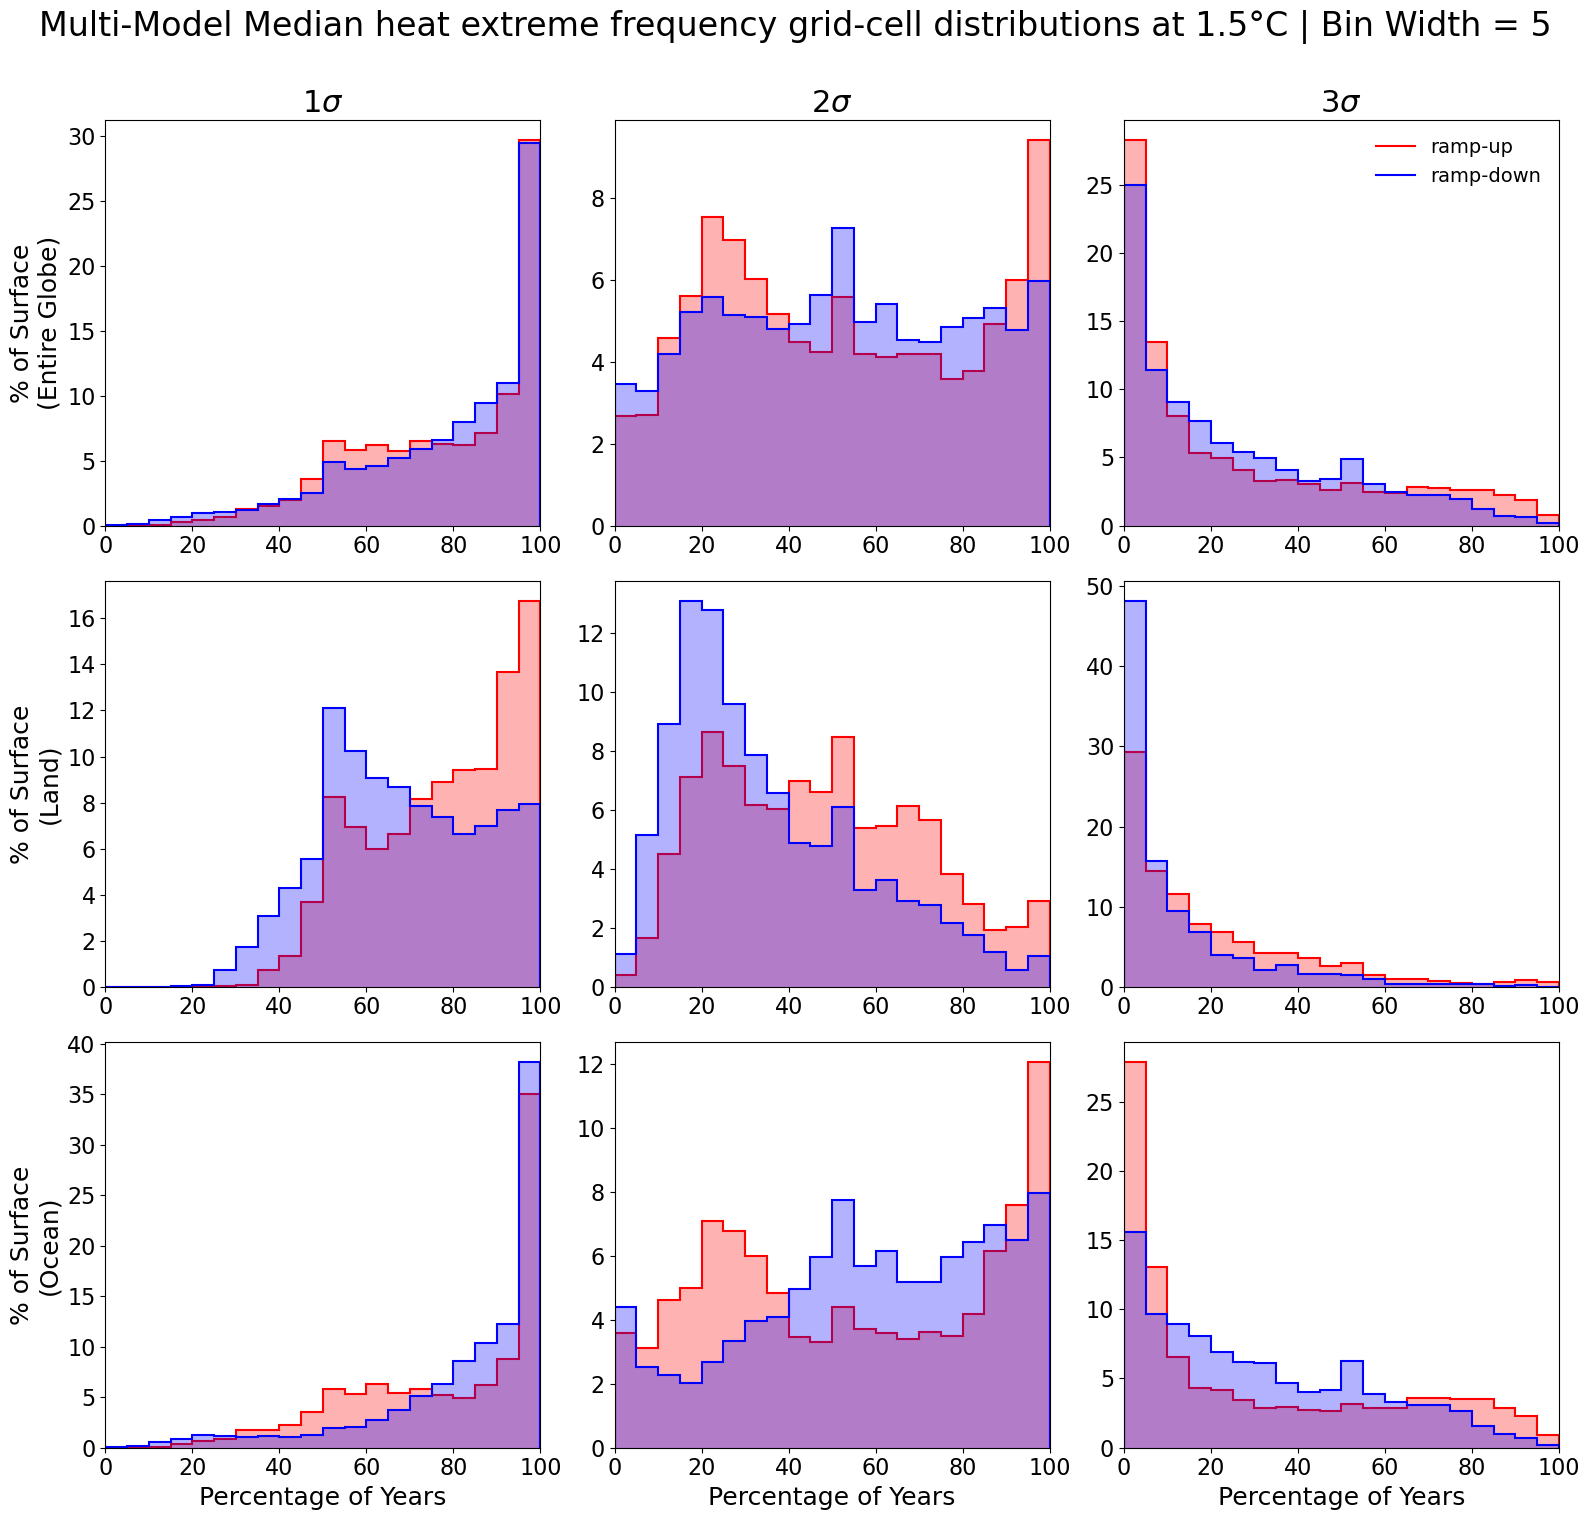

In [18]:
fig = plot_ext_freq_histogram_by_surface(
    exceedances, 'multi_model_median', '1pctCO2-cdr', 'heat', 1.5,
    land_mask, ocean_mask, bin_width=5, model_name = "Multi-Model Median"
)
fig.savefig(
    FIG_DIR / "supplementary" / "figure_S13.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)

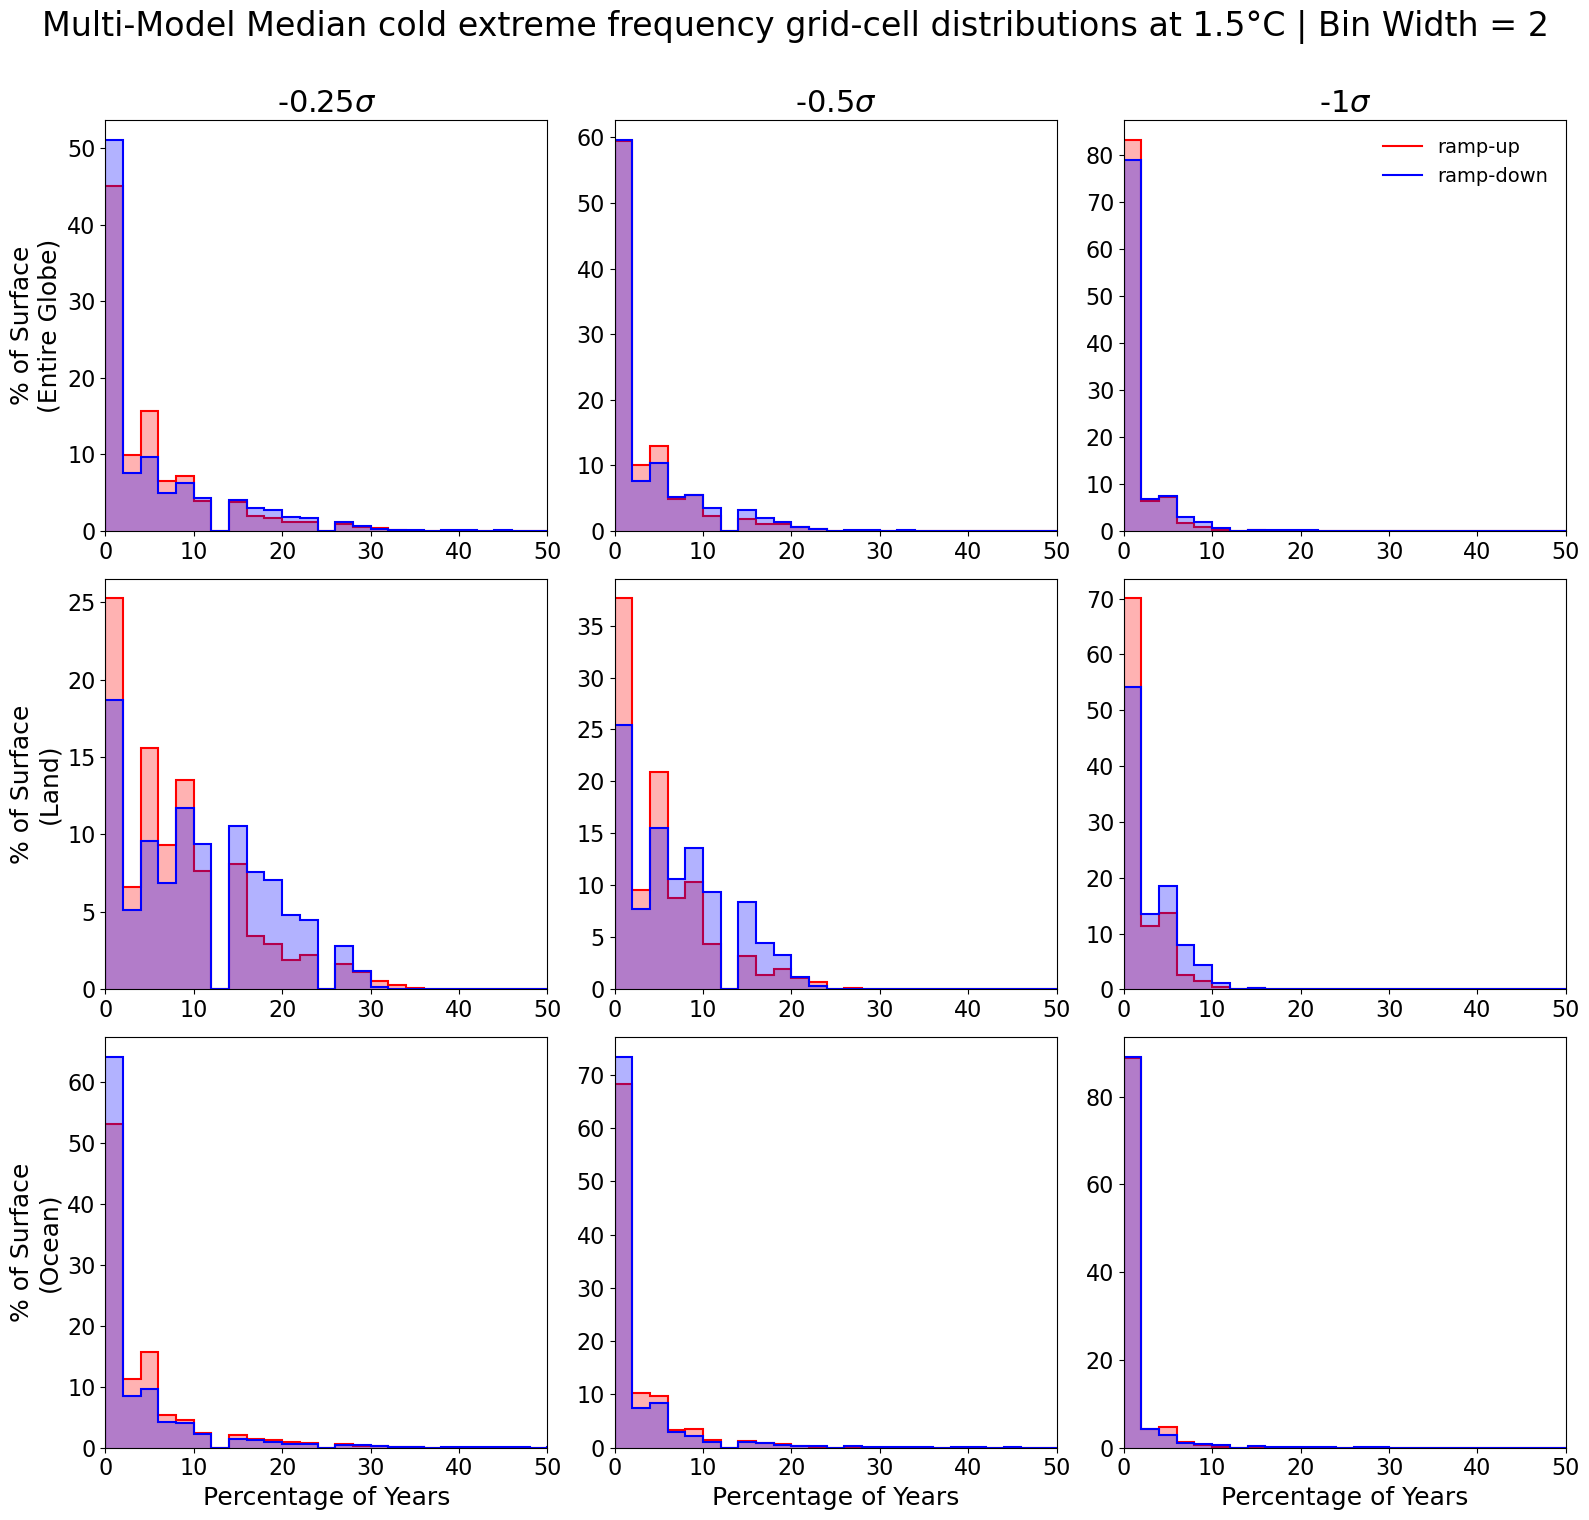

In [19]:
fig = plot_ext_freq_histogram_by_surface(
    exceedances, 'multi_model_median', '1pctCO2-cdr', 'cold', 1.5,
    land_mask, ocean_mask, bin_width=2, model_name = "Multi-Model Median"
)
fig.savefig(
    FIG_DIR / "supplementary" / "figure_S14.jpg",
    dpi=300,
    bbox_inches="tight",
    pil_kwargs={"quality": 95}
)